I loaded the Palmer Penguines dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("penguins.csv")
df.head()

# Drop the 2 empty rows, tidy the sex labels, fill missing sex
df_clean = df.dropna(subset=["body_mass_g"]).copy()
df_clean["sex"] = df_clean["sex"].str.title().fillna("Unknown")

num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(df_clean.shape)

(342, 7)


Histogram : This histogram shows how many penguins fall into each body mass range. The curve on top shows the overall shape. It helps me see where most penguins sit and whether the weights are spread evenly or bunched together

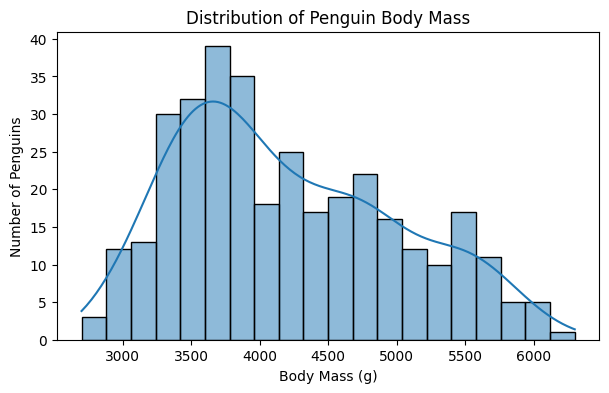

In [3]:
plt.figure(figsize=(7, 4))
sns.histplot(df_clean["body_mass_g"], bins=20, kde=True)
plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (g)")
plt.ylabel("Number of Penguins")
plt.show()

Bar chart  :This bar chart compares the average weight of the three species. It makes it easy to see which species is the heaviest and which is the lightest at a glance.

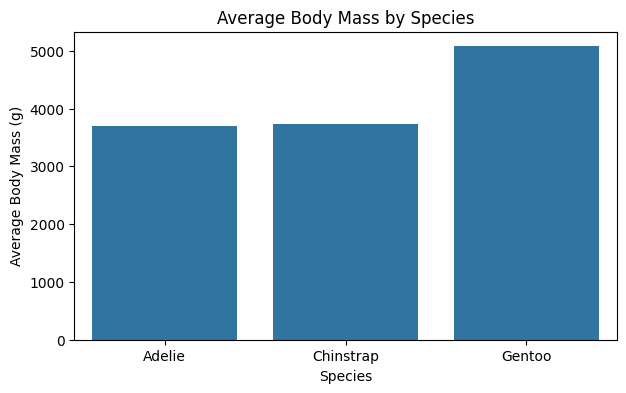

In [4]:
plt.figure(figsize=(7, 4))
sns.barplot(x="species", y="body_mass_g", data=df_clean, errorbar=None)
plt.title("Average Body Mass by Species")
plt.xlabel("Species")
plt.ylabel("Average Body Mass (g)")
plt.show()

Box Plot : This box plot shows the typical flipper length for each species and how much it varies. The box holds the middle half of the penguins, the line inside is the median, and the whiskers show the full normal range.

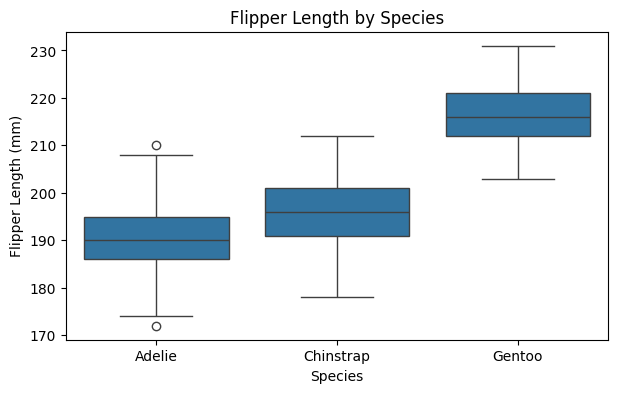

In [5]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="species", y="flipper_length_mm", data=df_clean)
plt.title("Flipper Length by Species")
plt.xlabel("Species")
plt.ylabel("Flipper Length (mm)")
plt.show()

Scatter Plot :Each dot is one penguin, colored by species. This chart shows whether penguins with longer flippers also weigh more, and whether the species form separate groups.

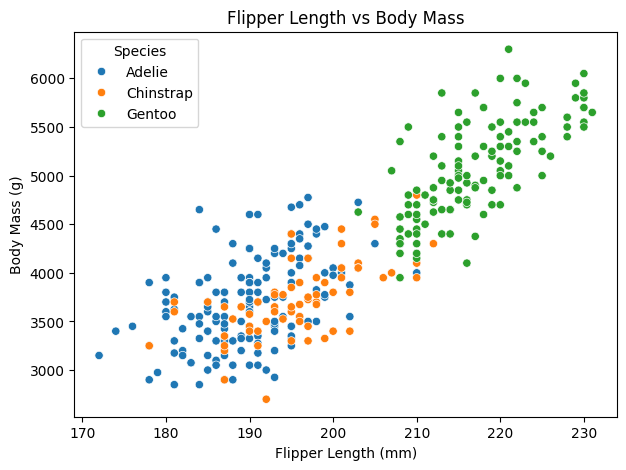

In [6]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x="flipper_length_mm", y="body_mass_g", hue="species", data=df_clean)
plt.title("Flipper Length vs Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.legend(title="Species")
plt.show()

Count Plot : This chart shows how many penguins of each species were recorded on each island. It shows which species live where and which island has the most penguins.

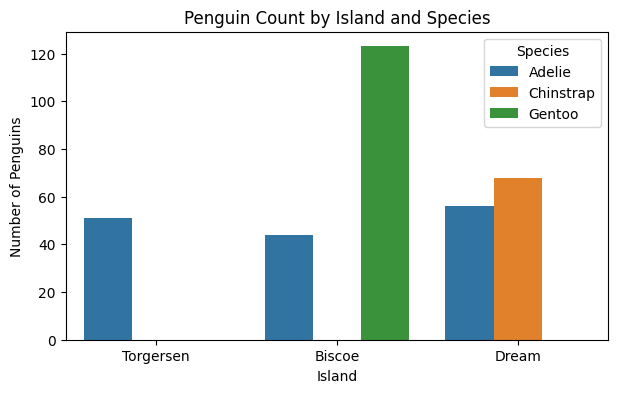

In [7]:
plt.figure(figsize=(7, 4))
sns.countplot(x="island", hue="species", data=df_clean)
plt.title("Penguin Count by Island and Species")
plt.xlabel("Island")
plt.ylabel("Number of Penguins")
plt.legend(title="Species")
plt.show()

Heat map : This heatmap shows how strongly the four measurements are related. Red squares mean two measurements rise together, blue means one rises while the other falls, and pale squares mean little relationship.

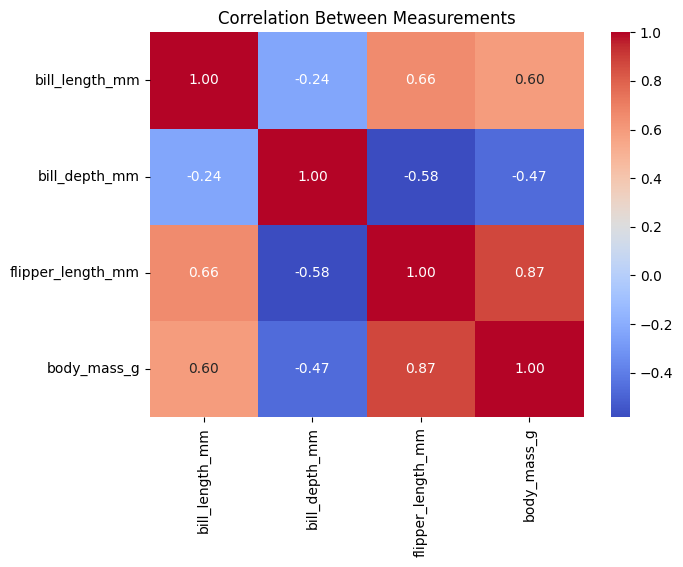

In [8]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_clean[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Measurements")
plt.show()